# 9장 딥 능동 학습

학생 모델을 사전학습 언어 모델 KLUE-RoBERTa로 바꾼다. run_loop 본문은 그대로 두고 `train_model` 과 `proba` 만 바꾼다. 결정적 엔트로피, MC 드롭아웃 엔트로피, BALD, 딥 모델 BADGE를 비교하고 재학습 방식(처음부터, 이어 학습)과 TF-IDF 학생 모델과의 차이를 잰다.

- 9.1 딥러닝 환경의 능동 학습 과제
- 9.2 KLUE-RoBERTa 학생 모델 파인튜닝
- 9.3 몬테카를로 드롭아웃(MC dropout)
- 9.4 BALD(Bayesian active learning by disagreement)
- 9.5 딥 모델 BADGE
- 9.6 재학습 전략 — 처음부터 재학습과 이어 학습
- 9.7 TF-IDF 학생 모델과의 비교

GPU 서버(NVIDIA RTX PRO 6000)에서 실행했다. 파인튜닝 비용 때문에 예산을 1,000으로 줄이고 질의 후보를 라운드마다 남은 풀에서 무작위 5,000개로 제한한다. 질의 크기 50과 시드 5개는 1부와 같다.

In [1]:
# ── 환경 설정과 상수 ────
import os
import time
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import torch
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup, logging as hf_logging
from sklearn.metrics import accuracy_score, f1_score
hf_logging.set_verbosity_error()

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 1000
N_CAND, T_MC = 5000, 10
MODEL_NAME = "klue/roberta-base"
EPOCHS, LR, BATCH = 5, 3e-5, 16
MAX_LEN = {"nsmc": 64, "ynat": 32}
DEV = "cuda"
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}
print("torch", torch.__version__, "| transformers", transformers.__version__, "|", torch.cuda.get_device_name(0))

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.12.0+cu132 | transformers 5.19.0 | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


## 9.2 KLUE-RoBERTa 학생 모델 파인튜닝

문장을 토큰으로 바꿔 입력 ID와 어텐션 마스크를 (샘플, 2, 길이) 텐서 하나에 담는다. 그래야 `data["X_pool"][idx]` 같은 1부의 인덱싱이 그대로 통한다. 최대 길이는 NSMC 64토큰, YNAT 제목 32토큰이다.

In [2]:
# ── 데이터와 토크나이저 ────
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(texts, max_len):
    e = tok(list(texts), truncation=True, max_length=max_len, padding="max_length", return_tensors="pt")
    return torch.stack([e.input_ids, e.attention_mask], 1)

def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    return dict(name=name, texts=pool.text.values, X_pool=encode(pool.text, MAX_LEN[name]), y_pool=pool.label.values,
                X_test=encode(test.text, MAX_LEN[name]), y_test=test.label.values, n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", tuple(d["X_pool"].shape), "시험", tuple(d["X_test"].shape), "클래스", d["n_classes"])

nsmc 풀 (20000, 2, 64) 시험 (10000, 2, 64) 클래스 2
ynat 풀 (20000, 2, 32) 시험 (9107, 2, 32) 클래스 7


학생 모델은 사전학습 가중치 위에 분류 헤드를 얹고 AdamW(학습률 3e-5, 배치 16, 5에폭, 웜업 10%)로 파인튜닝한다. 검증셋으로 조기 종료하지 않고 에폭 수를 고정한다. 헤드 크기는 라벨 집합의 가장 큰 클래스 번호로 정하고, 확률 함수는 1부처럼 빠진 클래스 열을 0으로 채운다. 연산은 bfloat16 자동 혼합 정밀도로 한다. GPU 연산의 비결정성 때문에 같은 시드라도 결과가 아주 조금 다를 수 있다.

In [3]:
# ── 학생 모델: KLUE-RoBERTa ────
class Student:
    def __init__(self, net):
        self.net = net
    def predict(self, X):
        return forward(self.net, X)[0].argmax(1)

def train_model(X, y, seed, init=None, epochs=EPOCHS):
    set_seed(seed)
    net = init.net if init else AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=int(y.max()) + 1).to(DEV)
    opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=0.01)
    steps = epochs * math.ceil(len(y) / BATCH)
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    yt, g = torch.as_tensor(y), torch.Generator().manual_seed(seed)
    net.train()
    for _ in range(epochs):
        for b in torch.randperm(len(y), generator=g).split(BATCH):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                loss = net(input_ids=X[b, 0].to(DEV), attention_mask=X[b, 1].to(DEV), labels=yt[b].to(DEV)).loss
            loss.backward()
            opt.step()
            sch.step()
            opt.zero_grad()
    return Student(net)

@torch.no_grad()
def forward(net, X, mc=False, bs=512):
    # 확률과 분류 헤드 마지막 층의 입력 표현 h를 돌려준다. mc=True면 드롭아웃을 켠 채 추론한다
    net.train(mc)
    P, H = [], []
    for i in range(0, len(X), bs):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            hid = net.roberta(input_ids=X[i:i + bs, 0].to(DEV), attention_mask=X[i:i + bs, 1].to(DEV)).last_hidden_state[:, 0]
            h = torch.tanh(net.classifier.dense(net.classifier.dropout(hid)))
            logit = net.classifier.out_proj(net.classifier.dropout(h))
        P.append(logit.float().softmax(-1).cpu())
        H.append(h.float().cpu())
    return torch.cat(P).numpy(), torch.cat(H).numpy()

def pad(P, n_classes):
    out = np.zeros(P.shape[:-1] + (n_classes,), dtype=np.float32)
    out[..., :P.shape[-1]] = P
    return out

def proba(model, X, n_classes):
    return pad(forward(model.net, X)[0], n_classes)

def proba_mc(model, X, n_classes, T=T_MC):
    return np.stack([pad(forward(model.net, X, mc=True)[0], n_classes) for _ in range(T)])   # (T, 샘플, 클래스)

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [4]:
# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))



# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l



# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)



# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

첫 점검으로 무작위 라벨 100개와 1,000개로 한 번씩 파인튜닝하고 학습 시간과 시험 성능을 본다. 3장의 TF-IDF 무작위 기준선(시드 5개 평균)을 같은 라벨 수에서 함께 출력한다.

In [5]:
# ── 첫 점검: 라벨 100·1,000 ────
check = []
for name, d in DATA.items():
    tfidf = pd.read_csv(f"results/ch03_{name}.csv").query("strategy == 'Random'").groupby("n_labeled").f1.mean()
    for n in (100, 1000):
        idx = np.random.default_rng(0).choice(len(d["y_pool"]), n, replace=False)
        t0 = time.perf_counter()
        m = train_model(d["X_pool"][idx], d["y_pool"][idx], 0)
        t_train = time.perf_counter() - t0
        f1 = f1_score(d["y_test"], m.predict(d["X_test"]), average="macro")
        check.append(dict(data=name, n=n, t_train=round(t_train, 1), f1_roberta=round(f1, 4), f1_tfidf_mean=round(tfidf.loc[n], 4)))
        del m
        torch.cuda.empty_cache()
print(pd.DataFrame(check).to_string(index=False))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9496.03it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9461.34it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9200.19it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 10132.91it/s]

data    n  t_train  f1_roberta  f1_tfidf_mean
nsmc  100      4.1      0.7374         0.5681
nsmc 1000     13.1      0.8343         0.7530
ynat  100      1.8      0.4867         0.2276
ynat 1000     12.2      0.8146         0.5555


## 9.3 몬테카를로 드롭아웃

드롭아웃을 켠 채 T = 10번 추론하면 매번 다른 확률이 나온다. 그 평균을 예측 분포로 쓰는 것이 MC 드롭아웃(Gal·Ghahramani 2016)이다. 먼저 보정(calibration)을 비교한다. 무작위 라벨 100개와 1,000개로 학습한 모델(시드 0)의 시험셋 확률로 기대 보정 오차(expected calibration error, ECE, 구간 10개)를 결정적 추론과 MC 추론에서 잰다.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9123.19it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8365.76it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9356.77it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8367.37it/s]

data    n    mode    ECE     f1  mean_conf
nsmc  100     결정적 0.1316 0.7374     0.6059
nsmc  100 MC 드롭아웃 0.1542 0.7482     0.5941
nsmc 1000     결정적 0.1192 0.8343     0.9539
nsmc 1000 MC 드롭아웃 0.0908 0.8354     0.9263
ynat  100     결정적 0.3089 0.4867     0.2117
ynat  100 MC 드롭아웃 0.3306 0.4840     0.2083
ynat 1000     결정적 0.0631 0.8146     0.8726
ynat 1000 MC 드롭아웃 0.0217 0.8191     0.8370


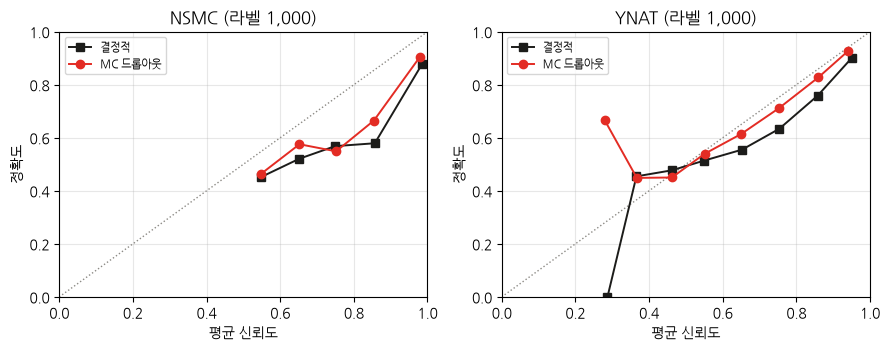

In [6]:
# ── 보정 진단 ────
def ece(P, y, bins=10):
    conf, pred = P.max(1), P.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    which = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)
    return sum((which == b).mean() * abs((pred[which == b] == y[which == b]).mean() - conf[which == b].mean())
               for b in range(bins) if (which == b).any())

def reliability(P, y, bins=10):
    conf, ok = P.max(1), P.argmax(1) == y
    which = np.clip(np.digitize(conf, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    return pd.DataFrame(dict(b=which, conf=conf, ok=ok)).groupby("b").agg(conf=("conf", "mean"), acc=("ok", "mean"), n=("ok", "size"))

calib, rel = [], {}
for name, d in DATA.items():
    for n in (100, 1000):
        idx = np.random.default_rng(0).choice(len(d["y_pool"]), n, replace=False)
        m = train_model(d["X_pool"][idx], d["y_pool"][idx], 0)
        P_det = proba(m, d["X_test"], d["n_classes"])
        P_mc = proba_mc(m, d["X_test"], d["n_classes"]).mean(0)
        for mode, P in (("결정적", P_det), ("MC 드롭아웃", P_mc)):
            calib.append(dict(data=name, n=n, mode=mode, ECE=round(ece(P, d["y_test"]), 4),
                              f1=round(f1_score(d["y_test"], P.argmax(1), average="macro"), 4), mean_conf=round(P.max(1).mean(), 4)))
            rel[name, n, mode] = reliability(P, d["y_test"])
        del m
        torch.cuda.empty_cache()
print(pd.DataFrame(calib).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, name in zip(axes, DATA):
    ax.plot([0, 1], [0, 1], color=GRAY2, ls=":", lw=1)
    for mode, c, mk in (("결정적", INK, "s"), ("MC 드롭아웃", ACCENT, "o")):
        r = rel[name, 1000, mode]
        ax.plot(r.conf, r.acc, color=c, marker=mk, lw=1.4, label=mode)
    ax.set(title=f"{name.upper()} (라벨 1,000)", xlabel="평균 신뢰도", ylabel="정확도", xlim=(0, 1), ylim=(0, 1))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("out/ch09_reliability.png", dpi=200)

## 9.4 BALD와 9.5 딥 모델 BADGE

질의 함수 넷을 2장 시그니처로 쓴다. 모두 라운드마다 남은 풀에서 무작위 5,000개를 후보로 뽑고 그 안에서 고른다. BALD는 평균 확률의 엔트로피에서 각 회 엔트로피의 평균을 뺀 상호 정보량이다. 모델 파라미터에 대한 불확실성(인식적 불확실성)만 남긴다. BADGE는 8장과 같은 k-means++ 시딩을 쓰고 기울기 임베딩의 특징 자리에 분류 헤드 마지막 층의 입력 h(768차원)를 쓴다.

In [7]:
# ── 질의 함수 ────
def entropy(P):
    return -(P * np.log(P + 1e-12)).sum(-1)

def candidates(idx_u, rng):
    return rng.choice(idx_u, min(N_CAND, len(idx_u)), replace=False)

def query_entropy(model, data, idx_l, y_l, idx_u, k, rng):
    c = candidates(idx_u, rng)
    return c[np.argsort(-entropy(proba(model, data["X_pool"][c], data["n_classes"])))[:k]]

def query_mc_entropy(model, data, idx_l, y_l, idx_u, k, rng):
    c = candidates(idx_u, rng)
    return c[np.argsort(-entropy(proba_mc(model, data["X_pool"][c], data["n_classes"]).mean(0)))[:k]]

def query_bald(model, data, idx_l, y_l, idx_u, k, rng):
    c = candidates(idx_u, rng)
    PT = proba_mc(model, data["X_pool"][c], data["n_classes"])
    mi = entropy(PT.mean(0)) - entropy(PT).mean(0)        # 전체 불확실성 − 우연적 불확실성
    return c[np.argsort(-mi)[:k]]

def kmeanspp(E, k, rng):
    sq = (E ** 2).sum(1)
    pick = [int(np.argmax(sq))]
    dist = sq + sq[pick[0]] - 2 * E @ E[pick[0]]
    for _ in range(k - 1):
        p = np.clip(dist, 0, None)
        j = int(rng.choice(len(E), p=p / p.sum()))
        pick.append(j)
        dist = np.minimum(dist, sq + sq[j] - 2 * E @ E[j])
    return np.array(pick)

def query_badge(model, data, idx_l, y_l, idx_u, k, rng):
    c = candidates(idx_u, rng)
    P, H = forward(model.net, data["X_pool"][c])
    G = pad(P, data["n_classes"])
    G[np.arange(len(G)), G.argmax(1)] -= 1                # p − e_ŷ
    E = (G[:, :, None] * H[:, None, :]).reshape(len(G), -1)
    return c[kmeanspp(E, k, rng)]

STRATS = {"Random": query_random, "엔트로피": query_entropy, "MC 엔트로피": query_mc_entropy,
          "BALD": query_bald, "BADGE": query_badge}

실험은 GPU 하나에서 차례로 돈다. (데이터, 전략, 시드)마다 결과를 `results/ch09_parts/` 에 저장해 실행이 끊겨도 이어서 돌 수 있게 한다. 라운드마다 학습 시간도 함께 남긴다.

In [8]:
# ── 능동 학습 실험 ────
os.makedirs("results/ch09_parts", exist_ok=True)
BASE_TRAIN = train_model

def timed(trainer, times):
    def fn(X, y, seed):
        t0 = time.perf_counter()
        m = trainer(X, y, seed)
        times.append(time.perf_counter() - t0)
        return m
    return fn

def run_cached(tag, query_fn, d, seed, trainer=BASE_TRAIN):
    global train_model
    path = f"results/ch09_parts/{d['name']}_{tag}_{seed}.csv"
    if os.path.exists(path):
        return pd.read_csv(path)
    times = []
    train_model = timed(trainer, times)
    t0 = time.perf_counter()
    df, _ = run_loop(query_fn, make_sim_oracle(d["y_pool"]), d, seed)
    train_model = BASE_TRAIN
    df = df.assign(strategy=tag, t_train=times, wall=time.perf_counter() - t0)
    df.to_csv(path, index=False)
    torch.cuda.empty_cache()
    return df

res = {}
for name, d in DATA.items():
    t0 = time.perf_counter()
    res[name] = pd.concat([run_cached(tag, q, d, s) for tag, q in STRATS.items() for s in SEEDS], ignore_index=True)
    res[name].to_csv(f"results/ch09_{name}.csv", index=False)
    print(f"{name} 완료 {(time.perf_counter() - t0) / 60:.1f}분")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9343.55it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8429.94it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 7998.97it/s]

... (1,892 outputs left out)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9530.64it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8542.90it/s]

ynat 완료 90.7분



nsmc 매크로 F1 (라벨 100~1,000)
strategy    ALC  ALC_std  final     LE  t_query  t_train  wall_min
  Random 0.8322   0.0059 0.8475 1.3333   0.0000     7.07      2.94
    엔트로피 0.8048   0.0140 0.8559 1.2500   1.2216     7.07      3.35
 MC 엔트로피 0.8086   0.0117 0.8406 1.5385  13.2536     7.39      7.10
    BALD 0.7978   0.0223 0.7480 1.0526  13.4816     7.39      7.16
   BADGE 0.8011   0.0242 0.7491 1.5385   1.7356     7.24      3.58
nsmc 정확도
strategy    ALC  ALC_std  final     LE  t_query
  Random 0.8331   0.0042 0.8475 1.3333   0.0000
    엔트로피 0.8124   0.0084 0.8560 1.2500   1.2216
 MC 엔트로피 0.8170   0.0086 0.8409 1.5385  13.2536
    BALD 0.8074   0.0162 0.7810 1.0526  13.4816
   BADGE 0.8122   0.0162 0.7822 1.5385   1.7356

ynat 매크로 F1 (라벨 100~1,000)
strategy    ALC  ALC_std  final     LE  t_query  t_train  wall_min
  Random 0.7763   0.0084 0.8280 1.0526   0.0001     6.58      2.44
    엔트로피 0.7931   0.0167 0.8476 2.2222   0.6757     7.01      2.80
 MC 엔트로피 0.8059   0.0053 0.8486 2.2222   7.1

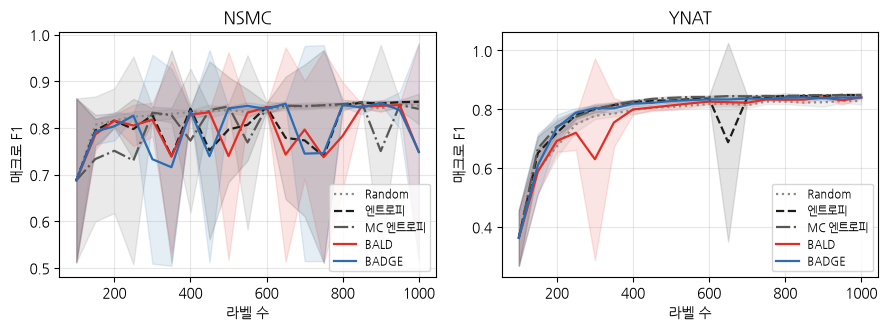

In [9]:
# ── 학습 곡선과 지표 ────
STYLES = [(GRAY2, ":"), (INK, "--"), (GRAY, "-."), (ACCENT, "-"), ("#2B6CB0", "-")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

for name, r in res.items():
    t = summarize(r, "f1").merge(r.groupby("strategy").agg(t_train=("t_train", "mean"), wall_min=("wall", lambda w: w.unique().mean() / 60)).round(2),
                                 on="strategy")
    print(f"\n{name} 매크로 F1 (라벨 100~1,000)")
    print(t.to_string(index=False))
    print(f"{name} 정확도")
    print(summarize(r, "acc").to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, res.items()):
    plot_curves(r, "f1", ax, name.upper())
fig.tight_layout()
fig.savefig("out/ch09_curves.png", dpi=200)

## 9.6 재학습 전략 — 처음부터 재학습과 이어 학습

지금까지는 라운드마다 사전학습 가중치에서 5에폭을 다시 학습했다. 이어 학습(warm start)은 첫 라운드만 5에폭을 학습하고 이후 라운드에서는 이전 라운드 모델을 늘어난 라벨 집합으로 1에폭만 더 학습한다. 엔트로피 전략으로 두 방식을 비교한다. 처음부터 재학습한 결과는 위 실험의 엔트로피 결과를 쓴다.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8819.75it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9521.20it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8917.31it/s]

... (12 outputs left out)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9046.87it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 11916.84it/s]


ynat 재학습 방식 (매크로 F1, LE 기준은 처음부터 재학습)
  strategy    ALC  ALC_std  final     LE  t_query  t_train  t_train_total
      엔트로피 0.7931   0.0167 0.8476 1.0526   0.6757     7.01         133.19
엔트로피·이어 학습 0.7811   0.0144 0.8329    NaN   0.6557     1.47          27.95


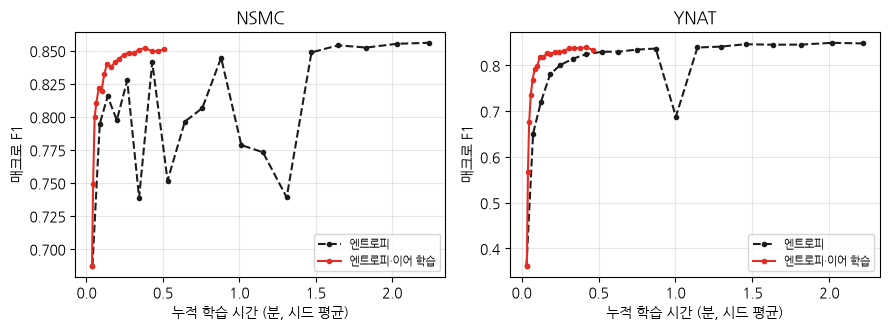

In [10]:
# ── 재학습 방식 비교 ────
def make_warm_trainer():
    st = dict(prev=None)
    def trainer(X, y, seed):
        st["prev"] = BASE_TRAIN(X, y, seed, init=st["prev"], epochs=1 if st["prev"] else EPOCHS)
        return st["prev"]
    return trainer

warm = {}
for name, d in DATA.items():
    w = pd.concat([run_cached("엔트로피·이어 학습", query_entropy, d, s, trainer=make_warm_trainer()) for s in SEEDS], ignore_index=True)
    warm[name] = pd.concat([res[name][res[name].strategy == "엔트로피"], w], ignore_index=True)
    warm[name].to_csv(f"results/ch09_warm_{name}.csv", index=False)
    t = summarize(warm[name], "f1", ref="엔트로피")
    t = t.merge(warm[name].groupby("strategy").agg(t_train=("t_train", "mean"), t_train_total=("t_train", lambda x: x.sum() / len(SEEDS))).round(2), on="strategy")
    print(f"\n{name} 재학습 방식 (매크로 F1, LE 기준은 처음부터 재학습)")
    print(t.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, w) in zip(axes, warm.items()):
    for (strat, g), (c, ls) in zip(w.groupby("strategy", sort=False), [(INK, "--"), (ACCENT, "-")]):
        m = g.groupby("n_labeled")
        ax.plot(m.t_train.sum().cumsum().values / len(SEEDS) / 60, m.f1.mean().values, color=c, ls=ls, marker="o", ms=3, lw=1.5, label=strat)
    ax.set(title=name.upper(), xlabel="누적 학습 시간 (분, 시드 평균)", ylabel="매크로 F1")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("out/ch09_warm.png", dpi=200)

## 9.7 TF-IDF 학생 모델과의 비교

3장 결과 파일에서 같은 라벨 구간(100~1,000)의 ALC를 다시 계산해 KLUE-RoBERTa 결과와 같은 표에 놓는다. 질의 크기가 50으로 같아서 측정점이 그대로 맞는다.

In [11]:
# ── TF-IDF 학생 모델과의 비교 ────
for name, r in res.items():
    tf = pd.read_csv(f"results/ch03_{name}.csv")
    tf = tf[tf.strategy.isin(["Random", "엔트로피"]) & (tf.n_labeled <= BUDGET)].assign(strategy=lambda x: "TF-IDF·" + x.strategy)
    both = pd.concat([tf, r.assign(strategy="RoBERTa·" + r.strategy)], ignore_index=True)
    t = summarize(both, "f1", ref="TF-IDF·Random")
    print(f"\n{name} 매크로 F1, 라벨 100~1,000 (LE 기준: TF-IDF Random의 라벨 1,000 성능)")
    print(t[["strategy", "ALC", "ALC_std", "final", "LE"]].to_string(index=False))


nsmc 매크로 F1, 라벨 100~1,000 (LE 기준: TF-IDF Random의 라벨 1,000 성능)
       strategy    ALC  ALC_std  final     LE
    TF-IDF·엔트로피 0.7184   0.0076 0.7584 1.0526
  TF-IDF·Random 0.7131   0.0077 0.7530 1.0000
 RoBERTa·Random 0.8322   0.0059 0.8475 6.6667
   RoBERTa·엔트로피 0.8048   0.0140 0.8559 6.6667
RoBERTa·MC 엔트로피 0.8086   0.0117 0.8406 3.3333
   RoBERTa·BALD 0.7978   0.0223 0.7480 6.6667
  RoBERTa·BADGE 0.8011   0.0242 0.7491 6.6667

ynat 매크로 F1, 라벨 100~1,000 (LE 기준: TF-IDF Random의 라벨 1,000 성능)
       strategy    ALC  ALC_std  final     LE
    TF-IDF·엔트로피 0.5317   0.0060 0.6532 2.0000
  TF-IDF·Random 0.4469   0.0142 0.5555 1.0000
 RoBERTa·Random 0.7763   0.0084 0.8280 6.6667
   RoBERTa·엔트로피 0.7931   0.0167 0.8476 6.6667
RoBERTa·MC 엔트로피 0.8059   0.0053 0.8486 6.6667
   RoBERTa·BALD 0.7703   0.0260 0.8405 6.6667
  RoBERTa·BADGE 0.7966   0.0098 0.8399 6.6667


### 파인튜닝 붕괴

NSMC 학습 곡선이 크게 출렁이는 까닭을 본다. 시험셋에서 매크로 F1이 0.5 아래로 떨어진 라운드를 붕괴 라운드로 센다. 이진 분류에서 한 클래스만 예측하면 매크로 F1이 0.33 안팎이 된다. 라벨 100개의 첫 라운드는 모든 전략이 같은 모델을 쓰므로 따로 센다. 시드별 평균 곡선 대신 라벨 수마다 시드 중앙값을 잡은 곡선의 ALC도 함께 계산한다.

In [12]:
# ── 파인튜닝 붕괴 집계 (결과 파일만 읽는다) ────
import numpy as np
import pandas as pd

def alc_curve(n, m, budget=1000):
    u = (n - n[0]) / (budget - n[0])
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

for name in ("nsmc", "ynat"):
    r = pd.read_csv(f"results/ch09_{name}.csv")
    w = pd.read_csv(f"results/ch09_warm_{name}.csv")
    r = pd.concat([r, w[w.strategy == "엔트로피·이어 학습"]], ignore_index=True)
    rows = []
    for s, g in r.groupby("strategy", sort=False):
        later = g[g.n_labeled > 100]
        med = g.groupby("n_labeled").f1.median()
        rows.append(dict(strategy=s, collapse_init=int((g[g.n_labeled == 100].f1 < 0.5).sum()),
                         collapse_later=int((later.f1 < 0.5).sum()), rounds_later=len(later),
                         seeds_hit=later[later.f1 < 0.5].seed.nunique(),
                         ALC_median=round(alc_curve(med.index.values, med.values), 4)))
    print(f"\n{name} 붕괴 라운드 (매크로 F1 < 0.5)")
    print(pd.DataFrame(rows).to_string(index=False))


nsmc 붕괴 라운드 (매크로 F1 < 0.5)
  strategy  collapse_init  collapse_later  rounds_later  seeds_hit  ALC_median
    Random              1               0            90          0      0.8348
      엔트로피              1               4            90          3      0.8378
   MC 엔트로피              1               5            90          4      0.8378
      BALD              1               5            90          3      0.8333
     BADGE              1               6            90          4      0.8361
엔트로피·이어 학습              1               0            90          0      0.8330

ynat 붕괴 라운드 (매크로 F1 < 0.5)
  strategy  collapse_init  collapse_later  rounds_later  seeds_hit  ALC_median
    Random              5               0            90          0      0.7768
      엔트로피              5               1            90          1      0.8025
   MC 엔트로피              5               0            90          0      0.8088
      BALD              5               2            90          1      0.7